In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

core = pd.read_csv(PROC / "core_retail_clean.csv", parse_dates=["date"])
core["ym"] = core["date"].dt.to_period("M")
CAL = pd.period_range("2016-01", "2026-06", freq="M")   # full 126-month calendar
BASE_YEAR = 2018                                         # full 12 months for every series
print(core.shape, "| commodities:", core["commodity"].nunique())

(29891, 12) | commodities: 5


In [2]:
def twoway_index(d, base_year=BASE_YEAR, tol=1e-10, max_iter=5000):
    """log(price) = market effect + month effect. Returns month index (base-year mean = 100)."""
    mk = d["market_id"].astype("category").cat.codes.to_numpy().astype(int)
    tmc = d["ym"].astype("category")
    tm = tmc.cat.codes.to_numpy().astype(int)
    months = tmc.cat.categories
    y = d["log_price"].to_numpy()
    b = np.zeros(len(months))
    for _ in range(max_iter):
        a = pd.Series(y - b[tm]).groupby(mk).mean().to_numpy()
        b_new = pd.Series(y - a[mk]).groupby(tm).mean().to_numpy()
        done = np.abs(b_new - b).max() < tol
        b = b_new
        if done:
            break
    s = pd.Series(b, index=months)
    base = s[[m for m in months if m.year == base_year]].mean()
    return np.exp(s - base) * 100

def n_components(d):
    """1 = markets and months form one connected network (index is identifiable)."""
    mk = d["market_id"].astype("category").cat.codes.to_numpy().astype(int)
    tm = d["ym"].astype("category").cat.codes.to_numpy().astype(int)
    nm, nt = mk.max() + 1, tm.max() + 1
    A = coo_matrix((np.ones(len(d)), (mk, nm + tm)), shape=(nm + nt, nm + nt))
    return connected_components(A + A.T, directed=False)[0]

def rebase(s, base_year=BASE_YEAR):
    return s / s[[m for m in s.index if m.year == base_year]].mean() * 100

In [3]:
out = []
for com, d in core.groupby("commodity"):
    print(f"{com:32s} connected components: {n_components(d)}")

    fe = twoway_index(d)
    naive = rebase(d.groupby("ym")["price"].median())
    mm = rebase(d[d["market"] == "Metro Manila"].set_index("ym")["price"])
    counts = d.groupby("ym").agg(n_markets=("market_id", "nunique"), n_obs=("price", "size"))

    t = (pd.DataFrame({"idx_fe": fe, "idx_naive": naive, "idx_mm": mm})
           .join(counts).reindex(CAL))
    t["commodity"] = com
    out.append(t)

res = pd.concat(out)
res.index.name = "ym"

print("\nMonths missing per commodity:", res.groupby("commodity")["idx_fe"].apply(lambda s: int(s.isna().sum())).to_dict())
print("Missing months:", [str(m) for m in res[res["idx_fe"].isna()].index.unique()])

Meat (beef, chops with bones)    connected components: 1
Meat (chicken, whole)            connected components: 1
Meat (pork)                      connected components: 1
Onions (red)                     connected components: 1
Rice (regular, milled)           connected components: 1

Months missing per commodity: {'Meat (beef, chops with bones)': 11, 'Meat (chicken, whole)': 11, 'Meat (pork)': 11, 'Onions (red)': 11, 'Rice (regular, milled)': 11}
Missing months: ['2019-06', '2019-07', '2019-08', '2019-09', '2019-10', '2019-11', '2019-12', '2020-01', '2020-02', '2020-03', '2020-04']


In [4]:
res["dev_vs_naive"] = (res["idx_fe"] / res["idx_naive"] - 1).abs()
print(res.groupby("commodity")["dev_vs_naive"].agg(["mean", "max"]).round(3))

summary = res.groupby("commodity")["idx_fe"].agg(["min", "max"]).round(1)
summary["peak_month"] = res.groupby("commodity")["idx_fe"].apply(lambda s: s.idxmax())
display(summary)

                                mean    max
commodity                                  
Meat (beef, chops with bones)  0.081  0.159
Meat (chicken, whole)          0.021  0.044
Meat (pork)                    0.055  0.130
Onions (red)                   0.051  0.131
Rice (regular, milled)         0.009  0.049


,min,max,peak_month
commodity,,,
"Meat (beef, chops with bones)",84.9,193.6,2026-05
"Meat (chicken, whole)",90.1,144.0,2025-07
Meat (pork),85.5,185.7,2025-06
Onions (red),67.2,526.8,2023-01
"Rice (regular, milled)",86.9,122.2,2024-04


In [5]:
B = ["Metro Manila", "Davao City", "Zamboanga City"]
print("First month each continuous market reports again after the gap:")
for m in B:
    mths = sorted(core[core["market"] == m]["ym"].unique())
    print(f"  {m:15s} last pre-gap: {[x for x in mths if x < pd.Period('2020-03')][-1]} | "
          f"first after gap: {[x for x in mths if x >= pd.Period('2020-05')][0]}")

rows = []
for com, t in res.groupby("commodity"):
    pre, post = t.loc["2019-03":"2019-05"], t.loc["2021-03":"2021-05"]
    rows.append({"commodity": com,
                 **{f"chg_{c}_%": round((post[c].mean() / pre[c].mean() - 1) * 100, 1)
                    for c in ["idx_fe", "idx_naive", "idx_mm"]}})
bridge = pd.DataFrame(rows).set_index("commodity")
print("\n% change, avg(Mar-May 2019) -> avg(Mar-May 2021):")
display(bridge)
bridge.to_csv(TAB / "05_bridge_comparison.csv")

First month each continuous market reports again after the gap:
  Metro Manila    last pre-gap: 2019-05 | first after gap: 2021-03
  Davao City      last pre-gap: 2019-05 | first after gap: 2022-01
  Zamboanga City  last pre-gap: 2019-05 | first after gap: 2022-01

% change, avg(Mar-May 2019) -> avg(Mar-May 2021):


,chg_idx_fe_%,chg_idx_naive_%,chg_idx_mm_%
commodity,,,
"Meat (beef, chops with bones)",37.0,21.8,20.1
"Meat (chicken, whole)",23.1,26.6,13.5
Meat (pork),45.2,32.0,62.5
Onions (red),99.7,87.1,75.0
"Rice (regular, milled)",-3.5,-5.3,-0.7


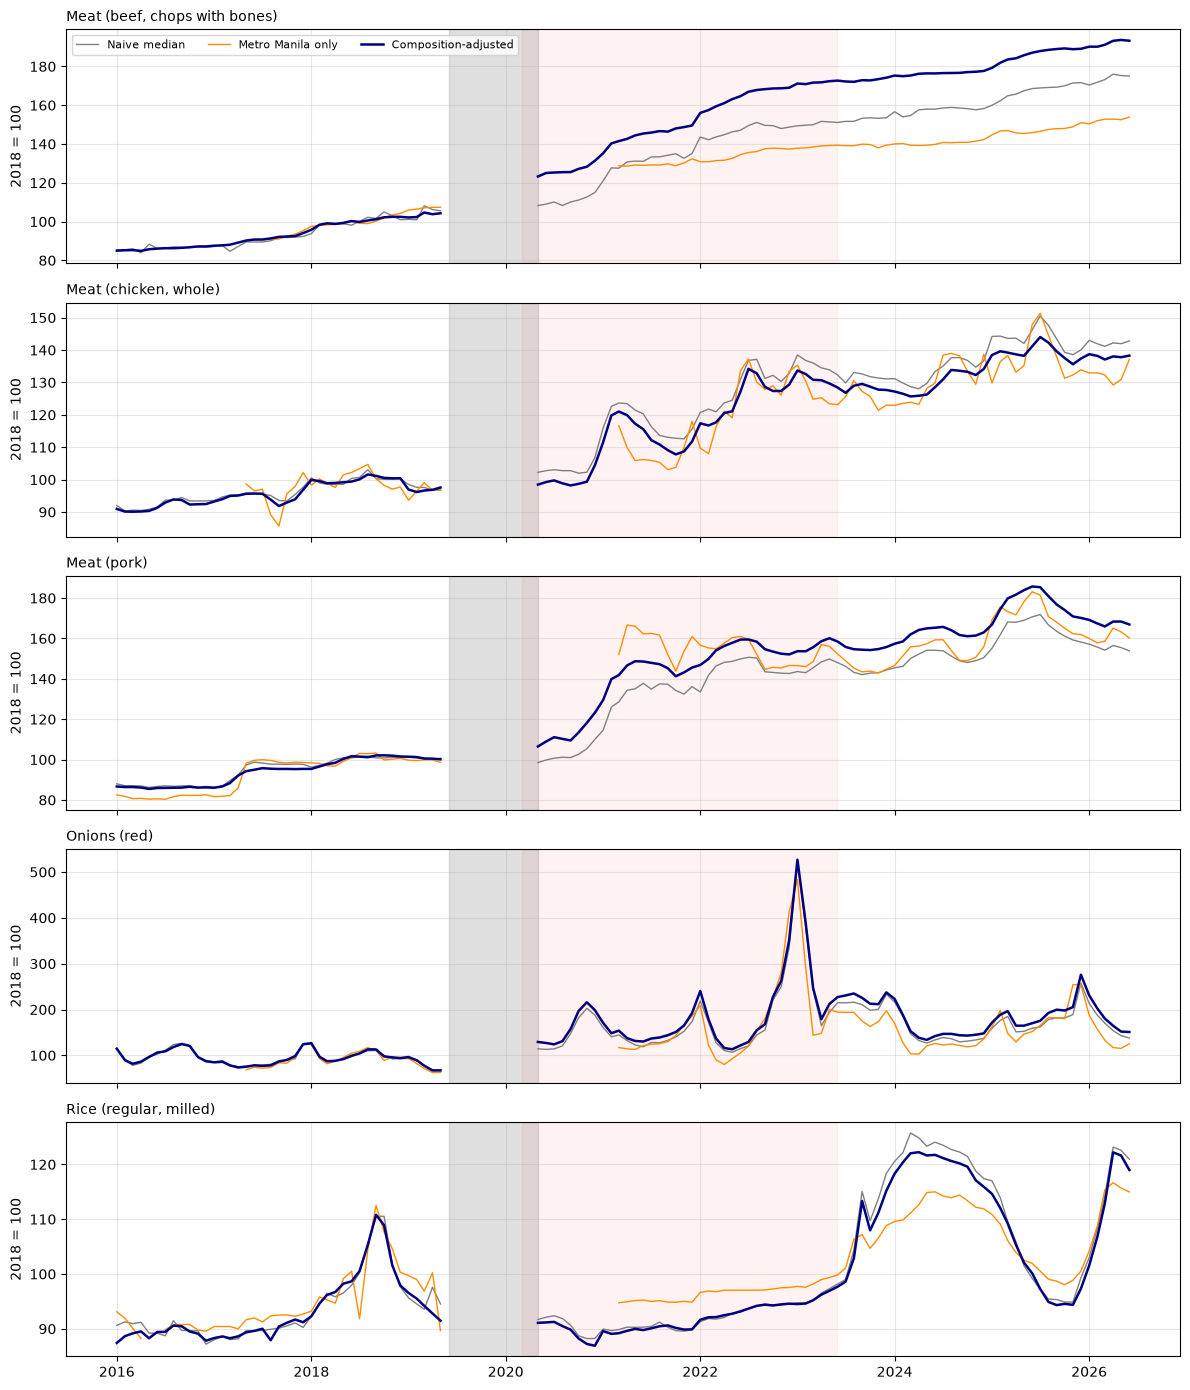

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
for ax, (com, t) in zip(axes, res.groupby("commodity")):
    x = t.index.to_timestamp()
    ax.plot(x, t["idx_naive"], color="grey", lw=1, label="Naive median")
    ax.plot(x, t["idx_mm"], color="darkorange", lw=1, label="Metro Manila only")
    ax.plot(x, t["idx_fe"], color="navy", lw=1.8, label="Composition-adjusted")
    ax.axvspan(pd.Timestamp("2019-06-01"), pd.Timestamp("2020-04-30"), color="grey", alpha=0.25)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2023-05-31"), color="red", alpha=0.05)
    ax.set_title(com, loc="left", fontsize=10); ax.set_ylabel("2018 = 100"); ax.grid(alpha=0.3)
axes[0].legend(ncol=3, loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "05_index_comparison.png", dpi=150)
plt.show()

In [7]:
def tag(p):
    return "Pre-COVID" if p < pd.Period("2020-03") else ("During-COVID" if p <= pd.Period("2023-05") else "Post-COVID")

save = res.drop(columns="dev_vs_naive").reset_index()
save["period"] = save["ym"].map(tag)
save["observed"] = save["idx_fe"].notna()
save["ym"] = save["ym"].astype(str)
save.to_csv(PROC / "national_monthly_index.csv", index=False)
print(save.shape)

(630, 9)
